# Bound bias-correction calibrations

The direct bound measure (`pigeon.data.get_bounds`: the midpoint of the positions on either side of
the inferred commit step) is biased: a single step can carry the pigeon well past the bound
(overshoot), the more so at short decision times (DT) and for small bounds relative to the step SD.
This notebook measures that bias by simulation and saves calibration tables that
`pigeon.data.apply_bias_corrections` inverts (given a measured |bound| at a DT and SNR, it returns
the true bound that produces it on average).

**Where the calibrations are used.** `get_data_table` applies them when asked
(`correct_bias=BIAS_CORRECTION_FILE`; off by default). No figure uses the corrected bound: the stopping model works
on raw positions, and Figure 4's adaptation curves and τ eligibility use raw bounds.

**Procedure**, for each SNR and each true bound in a grid: simulate 1,000,000 fixed-bound trials
(`simulate_trials`: no bound variability, NDT fixed at 1 step), measure each trial's bound with the
real-data estimator at that NDT (`get_bounds_from_dv`: peak-step rule, RT cutoff; trials with a
measured bound at the wall left out), and average |bound| at each DT. The NDT of 1 is the most
common per-subject estimate of `get_bounds` (see `Test_NDT`).

**Outputs** (`data/processed/`): `boundSummary[true bound, DT − 1, SNR bin]` (mean measured
|bound|), `simBounds` (the true bounds), `snrs` (the simulated SNRs) and `snrBinEdges` (the |SNR|
edges `apply_bias_corrections` bins trials by).

1. `boundBiasCorrection.mat` — cohorts 1 and 2 and the predefined-bound task (step SD 0.15; step
   means 0.05, 0.10, 0.15). PD bounds are set by the subject, so they are never corrected.
2. `boundBiasCorrection_CP.mat` — the change-point task (MXSC), whose steps are much smaller (SD
   0.05; means read from the data's fixed blocks), so the bias differs.

Runtime: about 30 minutes.

In [1]:
import sys
sys.path.insert(0, '..')

import matplotlib.pyplot as plt
import numpy as np
import scipy.io

from pigeon.data import WALL, get_bounds_from_dv, get_cp_generative_params, get_data_table
from pigeon.pathDefaults import BIAS_CORRECTION_CP_FILE, BIAS_CORRECTION_FILE
from pigeon.simulation import simulate_trials

NUM_TRIALS = 1_000_000   # trials per (true bound, SNR) run
FIXED_NDT = 1            # NDT of the simulated trials, and the lag the estimator uses
MAX_NDT = 5              # lags in the estimator's bound matrix (get_bounds' max_ndt)
SEED = 42


def get_mean_measured_bounds(choices, rts, DV, max_dt):
    """Mean measured |bound| at DT = 1..max_dt for simulated trials, measured as for real data."""
    bounds, dts, _, _, rt_cutoffs = get_bounds_from_dv(choices, rts, DV, max_ndt=MAX_NDT, ndt=FIXED_NDT,
                                                       rt_cutoff_threshold=0.65, peak_step_bound=True)
    keep = np.isfinite(bounds) & (np.abs(bounds) < WALL - 1e-9) & (rts >= rt_cutoffs)
    return np.array([np.mean(np.abs(bounds[keep & (dts == dt)])) if np.any(keep & (dts == dt)) else np.nan
                     for dt in range(1, max_dt + 1)])


def calibrate(generative_means, generative_std, sim_bounds, max_steps, max_dt, rng):
    """(n_bounds, max_dt, n_means) mean measured |bound| for each true bound and generative mean."""
    out = np.full((len(sim_bounds), max_dt, len(generative_means)), np.nan)
    for mm, mean in enumerate(generative_means):
        for ss, bound in enumerate(sim_bounds):
            choices, rts, DV, *_ = simulate_trials(
                generative_mean=mean, generative_std=generative_std, num_trials=NUM_TRIALS, max_steps=max_steps,
                bound_mean=bound, ndt_min=FIXED_NDT, ndt_max=FIXED_NDT, rng=rng, return_steps=False)
            out[ss, :, mm] = get_mean_measured_bounds(choices, rts, DV, max_dt)
        print(f'  step mean {mean:.3f}: {len(sim_bounds)} true bounds done')
    return out


def plot_calibration(bound_summary, sim_bounds, snrs, lim, n_dts=4):
    """Measured (x) vs. true (y) bound, one panel per DT (rows) and SNR (columns); dotted = identity."""
    fig, axs = plt.subplots(n_dts, len(snrs), figsize=(3 * len(snrs), 3 * n_dts), squeeze=False,
                            sharex=True, sharey=True)
    for dd in range(n_dts):
        for mm, snr in enumerate(snrs):
            ax = axs[dd, mm]
            ax.plot([0, lim], [0, lim], 'k:', lw=1)
            ok = np.isfinite(bound_summary[:, dd, mm])
            ax.plot(bound_summary[ok, dd, mm], sim_bounds[ok], 'r-', lw=2)
            ax.set_xlim(0, lim)
            ax.set_ylim(0, lim)
            ax.set_aspect('equal')
            if dd == 0:
                ax.set_title(f'SNR {snr:.2f}')
            if mm == 0:
                ax.set_ylabel(f'DT = {dd + 1}\ntrue bound')
            if dd == n_dts - 1:
                ax.set_xlabel('measured bound')
    plt.tight_layout()
    plt.show()

## 1. Cohorts 1 and 2 (`boundBiasCorrection.mat`)

True bounds 0.01–0.15 in steps of 0.02 (where the measured-vs-true curve bends) and 0.20–0.70 in steps
of 0.05; DT bins 1–12 (`apply_bias_corrections` uses the DT = 12 curve for longer trials); SNR bins
split at |SNR| = 0.4 and 0.8.

  step mean 0.050: 19 true bounds done


  step mean 0.100: 19 true bounds done


  step mean 0.150: 19 true bounds done
Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/data/processed/boundBiasCorrection.mat: boundSummary (19, 12, 3) (true bounds x DT x SNR)


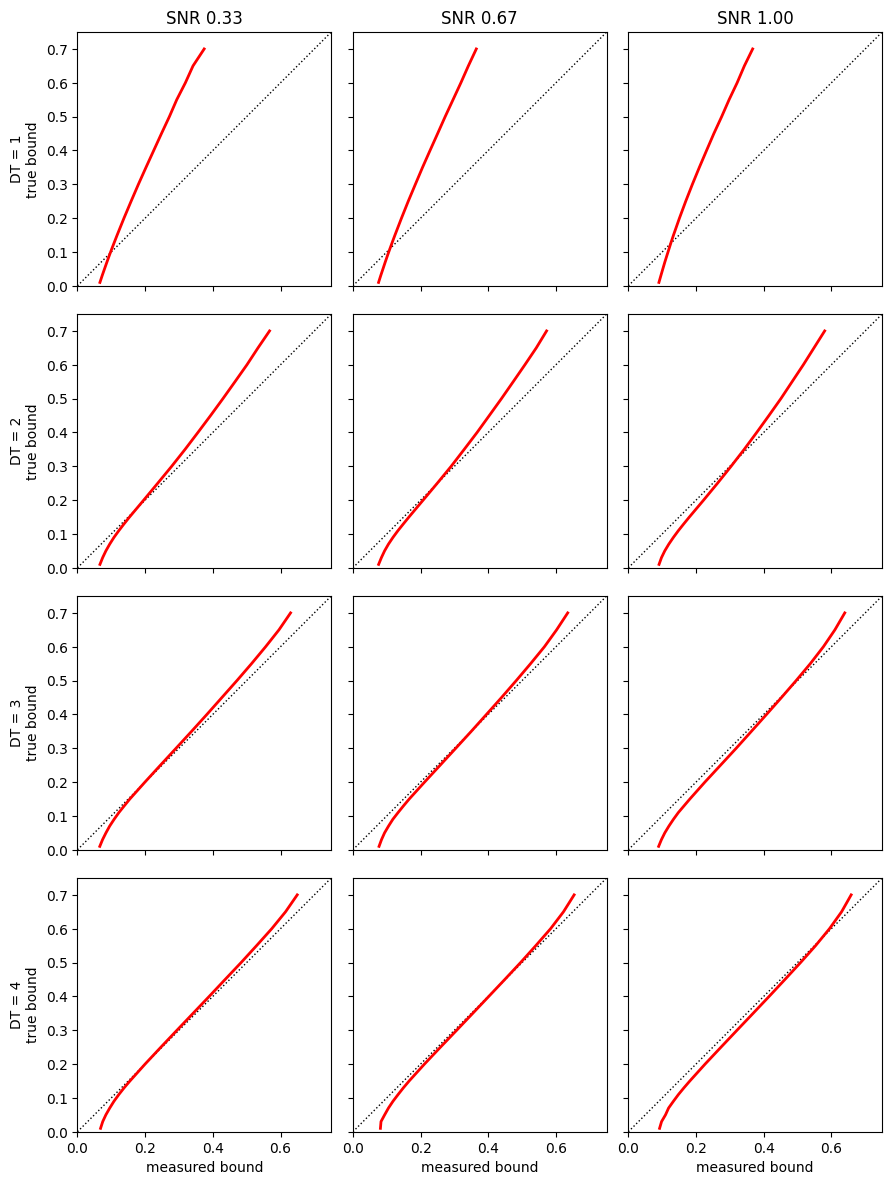

In [2]:
SIM_BOUNDS = np.concatenate([np.arange(0.01, 0.16, 0.02), np.arange(0.20, 0.71, 0.05)])
GENERATIVE_MEANS = np.array([0.05, 0.10, 0.15])   # SNR 0.33, 0.67, 1.0
GENERATIVE_STD = 0.15
SNRS = GENERATIVE_MEANS / GENERATIVE_STD

bound_summary = calibrate(GENERATIVE_MEANS, GENERATIVE_STD, SIM_BOUNDS, max_steps=50, max_dt=12,
                          rng=np.random.default_rng(SEED))
scipy.io.savemat(BIAS_CORRECTION_FILE, {'boundSummary': bound_summary, 'simBounds': SIM_BOUNDS, 'snrs': SNRS,
                                        'snrBinEdges': np.array([0.4, 0.8])})
print(f'Saved {BIAS_CORRECTION_FILE}: boundSummary {bound_summary.shape} (true bounds x DT x SNR)')
plot_calibration(bound_summary, SIM_BOUNDS, SNRS, lim=WALL)

## 2. Change-point task (`boundBiasCorrection_CP.mat`)

The task's two fixed conditions (step mean and SD of blocks 1 and 2, read from the data by
`get_cp_generative_params`, which raises if subjects' designs differ): SNR 0.2 (mean 0.01) and 0.6
(mean 0.03), SD 0.05. True bounds 0.002–0.020 in steps of 0.002 and 0.025–0.600 in steps of 0.025
(the data's 99th-percentile measured |bound| is about 0.47); trials up to 60 steps (the task's
maximum RT is 50); DT bins 1–35; SNR bins split at |SNR| = 0.3.

step means [0.01 0.03], SD 0.05, SNRs [0.2 0.6]


  step mean 0.010: 34 true bounds done


  step mean 0.030: 34 true bounds done
Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/data/processed/boundBiasCorrection_CP.mat: boundSummary (34, 35, 2) (true bounds x DT x SNR)


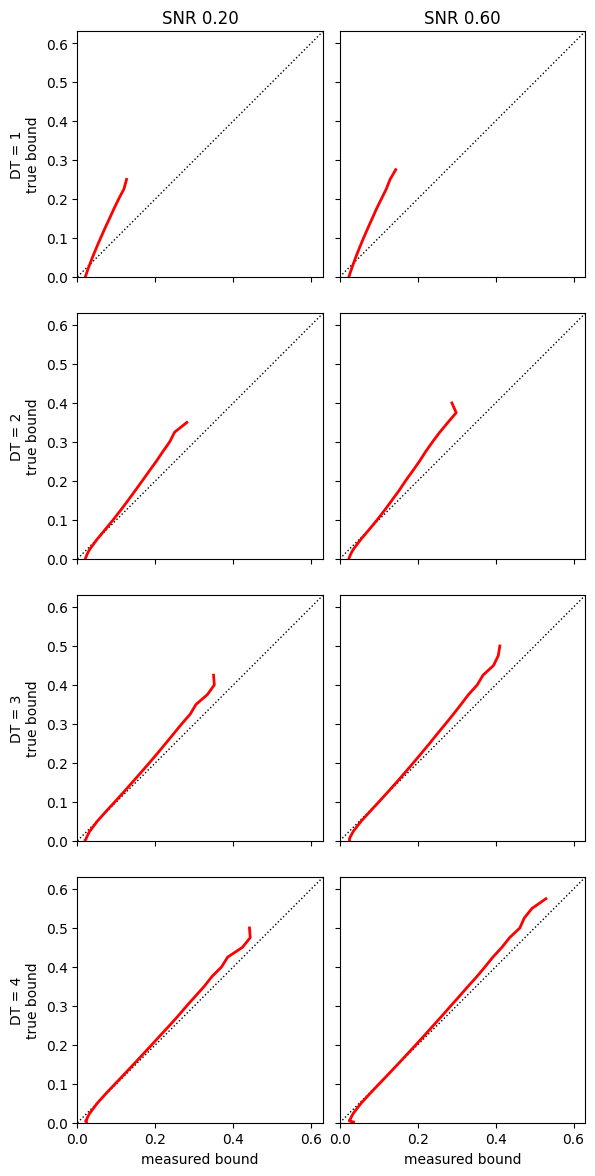

In [3]:
CP_SIM_BOUNDS = np.concatenate([np.arange(0.002, 0.021, 0.002), np.arange(0.025, 0.601, 0.025)])
cp_gen = get_cp_generative_params(get_data_table(task_type='MXSC', combine_snr=False, correct_bias=None))
CP_MEANS = np.array([cp_gen['low'][0], cp_gen['high'][0]])
CP_STD = cp_gen['low'][1]
assert cp_gen['high'][1] == CP_STD, 'the calibration assumes one step SD for both conditions'
CP_SNRS = CP_MEANS / CP_STD
print(f'step means {CP_MEANS}, SD {CP_STD}, SNRs {np.round(CP_SNRS, 3)}')

cp_bound_summary = calibrate(CP_MEANS, CP_STD, CP_SIM_BOUNDS, max_steps=60, max_dt=35,
                             rng=np.random.default_rng(SEED))
scipy.io.savemat(BIAS_CORRECTION_CP_FILE, {'boundSummary': cp_bound_summary, 'simBounds': CP_SIM_BOUNDS,
                                           'snrs': CP_SNRS, 'snrBinEdges': np.array([0.3])})
print(f'Saved {BIAS_CORRECTION_CP_FILE}: boundSummary {cp_bound_summary.shape} (true bounds x DT x SNR)')
plot_calibration(cp_bound_summary, CP_SIM_BOUNDS, CP_SNRS, lim=CP_SIM_BOUNDS.max() * 1.05)